# Values and numeric types

Convert five readings from Celsius to Fahrenheit and examine where arithmetic changes type.

The offset belongs after multiplication by the scale factor. Check the freezing point by hand, then inspect a value that would expose early integer division. All plotted points share the same transformation, so equal increments on the input scale must give equal increments on the output scale.

A vectorised expression applies one transformation to all observations. The scalar constants recycle to the vector length.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.R`

```r
celsius <- c(-10, 0, 10, 20, 30)
fahrenheit <- celsius * 9 / 5 + 32
cat(fahrenheit)
```

## Execute the native listing

A vectorised expression applies one transformation to all observations. The scalar constants recycle to the vector length. Inspect the object with str() before transforming it. Type, names, dimensions and missingness can all affect how an expression is evaluated.

In [2]:
x = [-10, 0, 10, 20, 30]
expected = np.asarray([9 * c / 5 + 32 for c in x], dtype=float)
engine, stdout = run_native(here / "native.R")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: R
Native stdout: 14 32 50 68 86
Largest absolute difference: 0


## Read the output

A straight line is expected. The intercept is 32 and a ten-degree Celsius step adds 18 degrees Fahrenheit. The marks show the independent Python reference at each position.

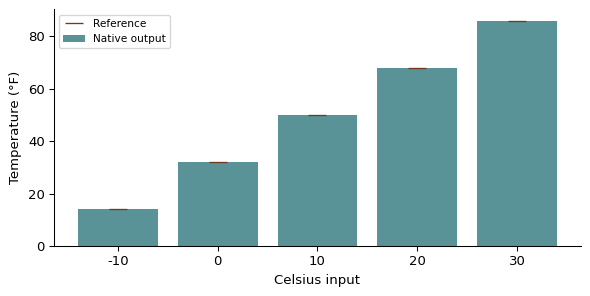

In [3]:
labels = [str(v) for v in x]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Celsius input", ylabel="Temperature (°F)")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

A straight line is expected. The intercept is 32 and a ten-degree Celsius step adds 18 degrees Fahrenheit.

## Exercise

Add −40 and a fractional Celsius reading. Describe any type change needed by the native programme.

## References

[R Core Team, An Introduction to R](https://cran.r-project.org/doc/manuals/r-release/R-intro.html)